<a href="https://colab.research.google.com/github/Mohammadi1994/Mohammadi1994/blob/main/practical_exercise_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# $\color{purple}{\text{Install yfinance}}$:

In [ ]:
pip install yfinance

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 50 kB 5.0 MB/s 
     |████████████████████████████████| 62 kB 1.7 MB/s 
     |████████████████████████████████| 4.0 MB 68.0 MB/s 
     |████████████████████████████████| 128 kB 82.7 MB/s 
     |████████████████████████████████| 112 kB 86.0 MB/s 
     |████████████████████████████████| 110 kB 76.9 MB/s 
  Attempting uninstall: requests
    Found existing installation: requests 2.23.0
    Uninstalling requests-2.23.0:
      Successfully uninstalled requests-2.23.0
  Attempting uninstall: html5lib
    Found existing installation: html5lib 1.0.1
    Uninstalling html5lib-1.0.1:
      Successfully uninstalled html5lib-1.0.1
  Attempting uninstall: beautifulsoup4
    Found existing installation: beautifulsoup4 4.6.3
    Uninstalling beautifulsoup4-4.6.3:
      Successfully uninstalled beautifulsoup4-4.6.3


# $\color{purple}{\text{import necessary libreries}}$:

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

We need perf_counter ​​to compare LSTM and GRU execution time.

In [ ]:
from time import perf_counter

# $\color{purple}{\text{Load data}}$:

In [ ]:
def get_stock_data(company, start_date, end_date):
    df = yf.download(company, start_date, end_date)
    stock_data = df[['High','Low']]
    return stock_data, df

In [ ]:
start_date = "2010-01-01"
end_date = "2020-01-01"
company = 'GOOG'
stock_data, df = get_stock_data(company, start_date, end_date)

[*********************100%***********************]  1 of 1 completed


In [ ]:
df


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-01-04,15.615220,15.678981,15.547723,15.610239,15.610239,78541293
2010-01-05,15.620949,15.637387,15.480475,15.541497,15.541497,120638494
2010-01-06,15.588072,15.588072,15.102393,15.149715,15.149715,159744526
2010-01-07,15.178109,15.193053,14.760922,14.797037,14.797037,257533695
2010-01-08,14.744733,15.024933,14.672753,14.994298,14.994298,189680313
...,...,...,...,...,...,...
2019-12-24,67.425003,67.513000,67.139000,67.178001,67.178001,6950000
2019-12-26,67.308502,68.066353,67.223503,68.019997,68.019997,13350000
2019-12-27,68.149498,68.226501,67.465500,67.594498,67.594498,20768000


In [ ]:
stock_data

,High,Low
Date,,
2010-01-04,15.678981,15.547723
2010-01-05,15.637387,15.480475
2010-01-06,15.588072,15.102393
2010-01-07,15.193053,14.760922
2010-01-08,15.024933,14.672753
...,...,...
2019-12-24,67.513000,67.139000
2019-12-26,68.066353,67.223503
2019-12-27,68.226501,67.465500


# $\color{purple}{\text{Plot High and Low price}}$:

🔶 High price plot

Text(0.5, 1.0, 'High price')

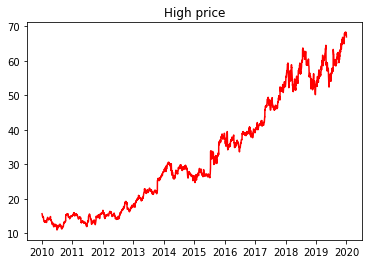

In [ ]:
plt.plot(stock_data.High, color = "red")
plt.title("High price")

🔷 Low price plot

Text(0.5, 1.0, 'Low price')

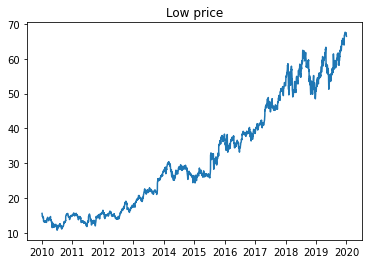

In [ ]:
plt.plot(stock_data.Low)
plt.title("Low price")

# $\color{purple}{\text{Normalization data}}$:

🔷 We took help from the following site to implement this part \
https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

* Why we use from sklearn.preprocessing import MinMaxScaler? \
$\color{red}{\text{Solution: Transform features by scaling each feature to a given range.}}$ \
* Why we use from fit_transform? \
$\color{green}{\text{Solution: To first fit the data and then transform it.}}$ \
We Normalizes  data using the MinMaxScaler with minimum and maximum values of -1 and 1, respectively

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(-1,1))
df['High'] = scaler.fit_transform(df['High'].values.reshape(-1,1))
df['Low'] = scaler.fit_transform(df['Low'].values.reshape(-1,1))

**To be able to work with stock_data, we convert it to numpy.**



In [ ]:
stock_data = df[['High','Low']]
stock_data = stock_data.to_numpy()

# $\color{purple}{\text{split dataset}}$:
we consider 80% dataset for train and 20% for test set

In [ ]:
training_size=int(len(stock_data)*0.80)
test_size=len(stock_data)-training_size
train_data,test_data=stock_data[0:training_size,:],stock_data[training_size:len(stock_data),:]

In [ ]:
training_size,test_size

(2012, 504)

Notice: We define the following function so that we can separate the data and their label. We do this for both training and test data.

In [ ]:
def create_dataset(dataset, seq_len=30):
	data_x, data_y = [], []
	for i in range(len(dataset)-seq_len-1):
		a = dataset[i:(i+seq_len), :]
		data_x.append(a)
		data_y.append(dataset[i + seq_len, :])
	return np.array(data_x), np.array(data_y)

In [ ]:
seq_len = 30
x_train, y_train = create_dataset(train_data, seq_len)
x_test, y_test = create_dataset(test_data, seq_len)

# $\color{purple}{\text{Convert numpy to torch}}$:
So far our data is of type numpy. Therefore, we need to convert them to an acceptable format for PyTorch, i.e. tensor. For this, we use the torch.from_numpy command.

In [ ]:
X_train = torch.from_numpy(x_train).type(torch.Tensor)
X_test = torch.from_numpy(x_test).type(torch.Tensor)
Y_train = torch.from_numpy(y_train).type(torch.Tensor)
Y_test = torch.from_numpy(y_test).type(torch.Tensor)

In [ ]:
X_train.size(), Y_train.size(), X_test.size(), Y_test.size()

(torch.Size([1981, 30, 2]),
 torch.Size([1981, 2]),
 torch.Size([473, 30, 2]),
 torch.Size([473, 2]))

# $\color{purple}{\text{Creat model(LSTM)}}$:
To design the RNN (LSTM) network in PyTorch, we take help from the following site. \
https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html \


In [ ]:
class LSTM_Model(nn.Module):
    def __init__(self, input_size = 2 , hidden_size = 100 , num_layers = 2, output_size = 2):
        super(LSTM_Model, self).__init__()
        self.hidden_size  = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_()
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_()
        output, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        output = self.linear(output[:, -1, :])
        return output

In [ ]:
lstm_model = LSTM_Model()

In [ ]:
print(lstm_model)

LSTM_Model(
  (lstm): LSTM(2, 100, num_layers=2, batch_first=True)
  (linear): Linear(in_features=100, out_features=2, bias=True)
)


# $\color{purple}{\text{Train Network}}$:
Training Network (derive training loss)\
**Notice**: In order to be able to plot the graph of loss train, we put a zero vector at the beginning and then we add the values ​​we get for loss to the vector each time.

In [ ]:
def training(lstm_model, criterion, optimizer, X_train, Y_train, num_epochs):
 train_loss = np.zeros(num_epochs)
 lstm = []
 tic_1 = perf_counter()
 for t in range(num_epochs):
    Y_train_predict = lstm_model(X_train)
    loss = criterion(Y_train_predict, Y_train)
    if t % 10 == 0 and t !=0:
        print("Epoch ", t, "MSE: ", loss.item())
    train_loss[t] = loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
 tic_2 = perf_counter()
 print(f"Time taken for the LSTM: {tic_2 - tic_1}")
 fig = plt.figure()
 plt.plot(train_loss, label="loss_train")
 plt.xlabel("Epoch")
 plt.ylabel("Loss train")
 plt.legend()
 plt.show()

# $\color{purple}{\text{Definition Loss and optimizer}}$:
First, we use MSE for loss and Adam for optimizer. \
Adam Algorithm = GD with momentum + RMS prop

In [ ]:
learning_rate = 0.001
criterion =  torch.nn.MSELoss()
optimizer1 = torch.optim.Adam(lstm_model.parameters(), lr=learning_rate)

Epoch  10 MSE:  0.1067608892917633
Epoch  20 MSE:  0.04721909388899803
Epoch  30 MSE:  0.015070942230522633
Epoch  40 MSE:  0.006108125206083059
Epoch  50 MSE:  0.0017051395261660218
Epoch  60 MSE:  0.0011321440106257796
Epoch  70 MSE:  0.0010247965110465884
Epoch  80 MSE:  0.0007887280080467463
Epoch  90 MSE:  0.0007713926024734974
Time taken for the LSTM: 131.19930891299998


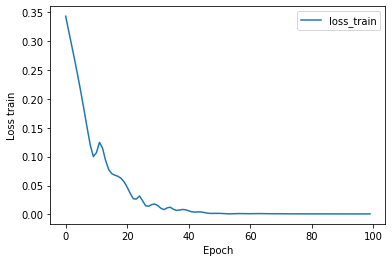

In [ ]:
train_loss = training(lstm_model, criterion, optimizer1, X_train, Y_train, num_epochs=100)

# $\color{purple}{\text{Calculate loss on test(LSTM Model)}}$:

 **comment**: During the test, there is no need to calculate the gradient, so we put it ⭐ with torch.no_grad():⭐

In [ ]:
def test(lstm_model, criterion, X_test, Y_test, num_epochs):
 with torch.no_grad():
  test_loss = np.zeros(num_epochs)
  lstm = []
  tic_1 = perf_counter()
  for t in range(num_epochs):
    Y_test_predict = lstm_model(X_test)
    loss = criterion(Y_test_predict, Y_test)
    print("Epoch ", t,  "MSE: ", loss.item())
    test_loss[t] = loss.item()
  tic_2 = perf_counter()
  print(f"Time taken for the LSTM: {tic_2 - tic_1}")
  fig = plt.figure()
  plt.plot(test_loss, label="loss_test")
  plt.xlabel("Epoch")
  plt.ylabel("Loss test")
  plt.legend()
  plt.show()

Epoch  0 MSE:  0.08643171191215515
Epoch  1 MSE:  0.12103555351495743
Epoch  2 MSE:  0.11270146816968918
Epoch  3 MSE:  0.08622799068689346
Epoch  4 MSE:  0.06862915307283401
Epoch  5 MSE:  0.06346606463193893
Epoch  6 MSE:  0.0645909458398819
Epoch  7 MSE:  0.06660880893468857
Epoch  8 MSE:  0.06669210642576218
Epoch  9 MSE:  0.06369427591562271
Time taken for the LSTM: 11.790104755000016


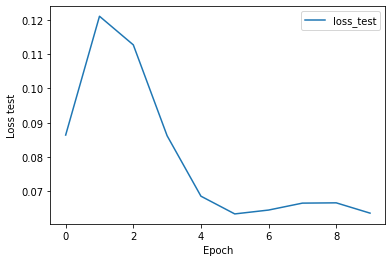

In [ ]:
test(lstm_model, criterion, X_test, Y_test, num_epochs=10)

# $\color{orange}{\text{Conclusions related to test loss(LSTM MODEL)}}$:
As we can see, the loss on the test is decreasing to some extent, but it is increasing to some extent. This suggests that we may have an error on the test loss and that our model may be overfitting.

# $\color{purple}{\text{Prediction for test}}$:

In [ ]:
Y_test_predict = lstm_model(X_test)

In [ ]:
prediction = pd.DataFrame(scaler.inverse_transform(Y_test_predict.detach().numpy()))
real = pd.DataFrame(scaler.inverse_transform(Y_test.detach().numpy()))

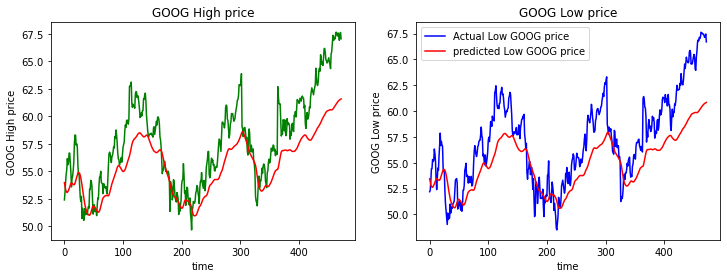

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(real[0], color='g', label=f'Actual High {company} price')
ax1.plot(prediction[0], color='r', label=f'predicted High  {company} price')
ax1.set_title(f'{company} High price')
ax1.set_xlabel('time')
ax1.set_ylabel(f'{company} High price')
ax2.plot(real[1], color='b', label=f'Actual Low {company} price')
ax2.plot(prediction[1], color='r', label=f'predicted Low {company} price')
ax2.set_title(f'{company} Low price')
ax2.set_xlabel('time')
ax2.set_ylabel(f'{company} Low price')
plt.legend()

# ploting 4 functions on the same figure
To make sure that the graphs related to high and low are not exactly on top of each other, we draw four functions on one figure. As you can see, the high and low plots are similar but not exactly the same. What is important is that low is lower, which is observed here.

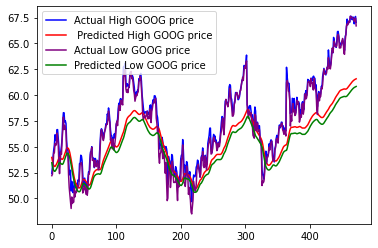

In [ ]:
plt.plot(real[0], color='b', label=f'Actual High {company} price')
plt.plot(prediction[0], color='r', label=f' Predicted High {company} price')
plt.plot(real[1], color='purple', label=f'Actual Low {company} price')
plt.plot(prediction[1], color='g', label=f'Predicted Low {company} price')
plt.legend()

#  **If we use of RMSProp optimizer**

In [ ]:
optimizer2 = torch.optim.RMSprop(lstm_model.parameters(), lr= learning_rate, alpha=0.99, eps=1e-08)

Epoch  10 MSE:  0.002248447621241212
Epoch  20 MSE:  0.0010015530278906226
Epoch  30 MSE:  0.002030343748629093
Epoch  40 MSE:  0.0009372708154842257
Epoch  50 MSE:  0.0009481268934905529
Epoch  60 MSE:  0.0025412871036678553
Epoch  70 MSE:  0.0016923056682571769
Epoch  80 MSE:  0.0010752163361757994
Epoch  90 MSE:  0.0013965079560875893
Time taken for the LSTM: 150.966481165


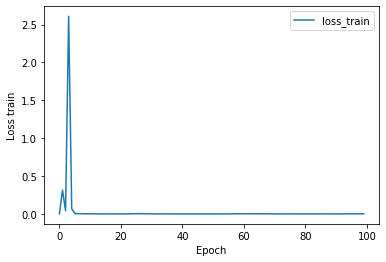

In [ ]:
train_loss = training(lstm_model, criterion, optimizer2, X_train, Y_train, num_epochs=100)

# $\color{purple}{\text{Report}}$:
As we know, the training data should show decreasing trend loss values. If we consider the minimizer as Adam. The decreasing loss trend is clearly visible. But in the RMsProp minimizer, the loss reduction process is very slow, and in some epochs the value has increased.

# $\color{purple}{\text{Definition MAPE}}$:
The reference of the sentences that are expressed is the following site \
https://pypi.org/project/torchmetrics/ \
⭐ TorchMetrics ▶ Machine learning metrics for distributed, scalable PyTorch applications. ⭐\
TorchMetrics is a collection of 90+ PyTorch metrics implementations and an easy-to-use API to create custom metrics. It offers: \
* A standardized interface to increase reproducibility\
* Reduces boilerplate \
* Automatic accumulation over batches \
* Metrics optimized for distributed-training \
* Automatic synchronization between multiple devices


# Installation TorchMetrics  from PyPI

In [ ]:
pip install torchmetrics

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


✍ We took help from the following site to implement MAPE in TorchMetrics. \
https://torchmetrics.readthedocs.io/en/stable/regression/mean_absolute_percentage_error.html

# If we use Adam optimizer and MAPE

In [ ]:
from torchmetrics import MeanAbsolutePercentageError

In [ ]:
mape_loss = MeanAbsolutePercentageError()
learning_rate = 0.001
optimizer1 = torch.optim.Adam(lstm_model.parameters(), lr=learning_rate)

In [ ]:
def training_mape(lstm_model, mape_loss, optimizer, X_train, Y_train, num_epochs):
 train_loss = np.zeros(num_epochs)
 lstm = []
 for t in range(num_epochs):
    Y_train_predict = lstm_model(X_train)
    loss = mape_loss(Y_train_predict, Y_train)
    if t % 10 == 0 and t !=0:
        print("Epoch ", t, "MAPE: ", loss.item())
    train_loss[t] = loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
 fig = plt.figure()
 plt.plot(train_loss, label="loss_train")
 plt.xlabel("Epoch")
 plt.ylabel("Loss train")
 plt.legend()
 plt.show()

Epoch  10 MAPE:  0.43388426303863525
Epoch  20 MAPE:  0.28064048290252686
Epoch  30 MAPE:  0.2572232186794281
Epoch  40 MAPE:  0.244851753115654
Epoch  50 MAPE:  0.2715069055557251
Epoch  60 MAPE:  0.2564235031604767
Epoch  70 MAPE:  0.23497340083122253
Epoch  80 MAPE:  0.2701795697212219
Epoch  90 MAPE:  0.25394827127456665


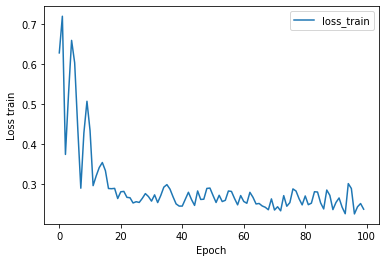

In [ ]:
train_loss_mape = training_mape(lstm_model, mape_loss, optimizer1, X_train, Y_train, num_epochs=100)

# If we use RMSProp optimizer and MAPE

Epoch  10 MAPE:  0.6293136477470398
Epoch  20 MAPE:  0.38749179244041443
Epoch  30 MAPE:  0.3790418803691864
Epoch  40 MAPE:  0.3483831286430359
Epoch  50 MAPE:  0.27288132905960083
Epoch  60 MAPE:  0.3835890293121338
Epoch  70 MAPE:  0.27504053711891174
Epoch  80 MAPE:  0.3291686475276947
Epoch  90 MAPE:  0.31219223141670227


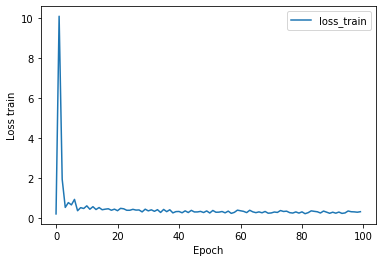

In [ ]:
train_loss_mape = training_mape(lstm_model, mape_loss, optimizer2, X_train, Y_train, num_epochs=100)

# $\color{purple}{\text{Creat model(GRU)}}$:
To design the RNN (GRU) network in PyTorch, we take help from the following site. \
https://pytorch.org/docs/stable/generated/torch.nn.GRU.html

In [ ]:
class GRU_model(nn.Module):
    def __init__(self, input_size = 2 , hidden_size = 100 , num_layers = 2, output_size = 2):
        super(GRU_model, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_()
        output, (hn) = self.gru(x, (h0.detach()))
        output = self.linear(output[:, -1, :])
        return output

In [ ]:
gru_model = GRU_model()

In [ ]:
print(gru_model)

GRU_model(
  (gru): GRU(2, 100, num_layers=2, batch_first=True)
  (linear): Linear(in_features=100, out_features=2, bias=True)
)


In [ ]:
learning_rate = 0.001
criterion =  torch.nn.MSELoss()
optimizer1 = torch.optim.Adam(gru_model.parameters(), lr=learning_rate)

In [ ]:
def training(gru_model, criterion, optimizer, X_train, Y_train, num_epochs):
 train_loss = np.zeros(num_epochs)
 gru = []
 tic_1 = perf_counter()
 for t in range(num_epochs):
    Y_train_predict = gru_model(X_train)
    loss = criterion(Y_train_predict, Y_train)
    if t % 10 == 0 and t !=0:
        print("Epoch ", t, "MSE: ", loss.item())
    train_loss[t] = loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
 tic_2 = perf_counter()
 print(f"Time taken for the GRU: {tic_2 - tic_1}")
 fig = plt.figure()
 plt.plot(train_loss, label="loss_train")
 plt.xlabel("Epoch")
 plt.ylabel("Loss train")
 plt.legend()
 plt.show()

Epoch  10 MSE:  0.08482589572668076
Epoch  20 MSE:  0.020045315846800804
Epoch  30 MSE:  0.003692897502332926
Epoch  40 MSE:  0.0018146381480619311
Epoch  50 MSE:  0.0014325937954708934
Epoch  60 MSE:  0.0004742682504002005
Epoch  70 MSE:  0.0005627677892334759
Epoch  80 MSE:  0.00044538715155795217
Epoch  90 MSE:  0.00043017129064537585
Time taken for the GRU: 122.98377700699893


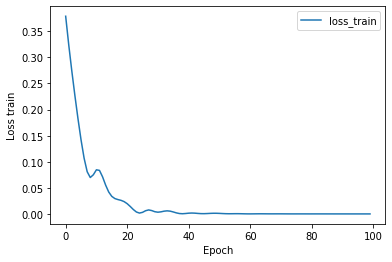

In [ ]:
train_loss = training(gru_model, criterion, optimizer1, X_train, Y_train, num_epochs=100)

# $\color{purple}{\text{Calculate loss on test(GRU Model)}}$:

In [ ]:
def test(gru_model, criterion, X_test, Y_test, num_epochs):
 with torch.no_grad():
  test_loss = np.zeros(num_epochs)
  gru = []
  tic_1 = perf_counter()
  for t in range(num_epochs):
    Y_test_predict = gru_model(X_test)
    loss = criterion(Y_test_predict, Y_test)
    print("Epoch ", t, "MSE: ", loss.item())
    test_loss[t] = loss.item()
  tic_2 = perf_counter()
  print(f"Time taken for the GRU: {tic_2 - tic_1}")
  fig = plt.figure()
  plt.plot(test_loss, label="loss_test")
  plt.xlabel("Epoch")
  plt.ylabel("Loss test")
  plt.legend()
  plt.show()

Epoch  0 MSE:  0.29629504680633545
Epoch  1 MSE:  0.2451123744249344
Epoch  2 MSE:  0.20040355622768402
Epoch  3 MSE:  0.16154012084007263
Epoch  4 MSE:  0.12896770238876343
Epoch  5 MSE:  0.10440978407859802
Epoch  6 MSE:  0.0907239243388176
Epoch  7 MSE:  0.08921512216329575
Epoch  8 MSE:  0.09333540499210358
Epoch  9 MSE:  0.09208579361438751
Time taken for the GRU: 10.738191435999852


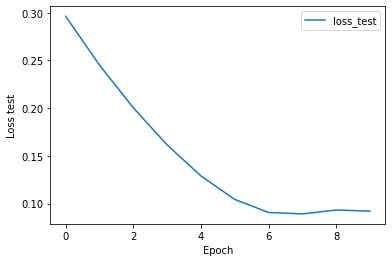

In [ ]:
test(gru_model, criterion, X_test, Y_test, num_epochs=10)

# $\color{orange}{\text{Conclusions related to test loss(GRU MODEL)}}$:
As we see. Compared to the test loss in the LSTM model, the test loss values ​​in the GRU model have a better decreasing trend. But again, in a time epoch, the amount of loss has increased.

# $\color{purple}{\text{comparing LSTM and GRU on training data}}$:
We also obtained training loss values ​​for LSTM and GRU. We also calculated the execution time of each. The execution time for each is as follows: \

Tables:

Model   | Time
-------------------|------------------
LSTM    | 131s
GRU  | 122s ✅

The results show that GRU is faster than LSTM. The training loss values ​​also show that the loss in the GRU model decreased more than in the LSTM and reached a very small value in the last epoch.

In [ ]:
Y_test_predict_gru = gru_model(X_test)

In [ ]:
prediction_gru = pd.DataFrame(scaler.inverse_transform(Y_test_predict_gru.detach().numpy()))
real = pd.DataFrame(scaler.inverse_transform(Y_test.detach().numpy()))

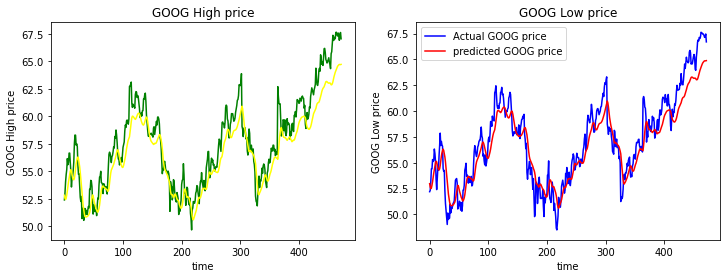

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(real[0], color='g', label=f'Actual {company} price')
ax1.plot(prediction_gru[0], color='yellow', label=f'predicted {company} price')
ax1.set_title(f'{company} High price')
ax1.set_xlabel('time')
ax1.set_ylabel(f'{company} High price')
ax2.plot(real[1], color='b', label=f'Actual {company} price')
ax2.plot(prediction_gru[1], color='r', label=f'predicted {company} price')
ax2.set_title(f'{company} Low price')
ax2.set_xlabel('time')
ax2.set_ylabel(f'{company} Low price')
plt.legend()

# $\color{purple}{\text{comparing LSTM and GRU on test data}}$:
By comparing the results of high and low in LSTM and GRU, we can conclude that the results in GRU are better than LSTM.
The predicted high and low values ​​in GRU are closer to the actual values ​​than LSTM. \
$\color{orange}{\text{So we conclude that GRU performs better than LSTM}}$

# $\color{purple}{\text{If we use dropout technique}}$:
👉 pytorch we use nn.Dropout(p=probability remove node)
* one of techniques that help to solve overfitting problem is, dropout. Overfitting problem when happens we have error on validation set. The loss decreases to a certain point, but it starts to increase from a certain point.

In [ ]:
class GRU_model_dropout(nn.Module):
    def __init__(self, input_size = 2 , hidden_size = 100 , num_layers = 2, output_size = 2):
        super(GRU_model_dropout, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = nn.Dropout(p=0.3)
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        h0 = torch.zeros(self.num_layers,  x.size(0), self.hidden_size).requires_grad_()
        output, (hn) = self.gru(x, (h0.detach()))
        output = self.dropout(output)
        output = self.linear(output[:, -1, :])
        output = self.dropout(output)
        return output

In [ ]:
gru_model_dropout = GRU_model_dropout()

# $\color{purple}{\text{Calculate loss on test(GRU Model with Dropout)}}$:

* Point: only in the train, used of dropout, and in tset, it's not used so we use of: $$ model.eval() ⇒ turn\ off\ dropout $$

In [ ]:
def test(gru_model_dropout, criterion, X_test, Y_test, num_epochs):
 with torch.no_grad():
  gru_model_dropout.eval()
  test_loss = np.zeros(num_epochs)
  gru = []
  tic_1 = perf_counter()
  for t in range(num_epochs):
    Y_test_predict = gru_model_dropout(X_test)
    loss = criterion(Y_test_predict, Y_test)
    print("Epoch ", t, "MSE: ", loss.item())
    test_loss[t] = loss.item()
  tic_2 = perf_counter()
  print(f"Time taken for the GRU: {tic_2 - tic_1}")
  fig = plt.figure()
  plt.plot(test_loss, label="loss_test")
  plt.xlabel("Epoch")
  plt.ylabel("Loss test")
  plt.legend()
  plt.show()

Epoch  0 MSE:  0.37712782621383667
Epoch  1 MSE:  0.3213140368461609
Epoch  2 MSE:  0.2712947130203247
Epoch  3 MSE:  0.22548389434814453
Epoch  4 MSE:  0.1828354448080063
Epoch  5 MSE:  0.14339680969715118
Epoch  6 MSE:  0.10862523317337036
Epoch  7 MSE:  0.0817590057849884
Epoch  8 MSE:  0.06769188493490219
Epoch  9 MSE:  0.0692131519317627
Time taken for the GRU: 9.524031394999952


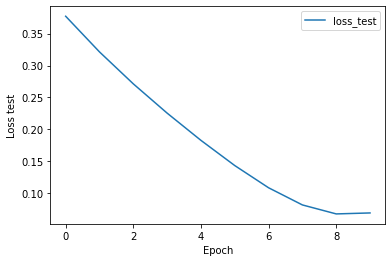

In [ ]:
test(gru_model_dropout, criterion, X_test, Y_test, num_epochs=10)

# $\color{purple}{\text{Result(GRU Model with Dropout)}}$:
As we can see, the loss graph is decreasing.

# $\color{purple}{\text{back test}}$:

In this section, we first specify the start and end date of the time data - the company name and the length of the time series.

In [ ]:
start_date = "2020-01-01"
end_date = "2021-01-01"
company = 'GOOG'
stock_data, df = get_stock_data(company, start_date, end_date)
stock_data

In [ ]:
scaler = MinMaxScaler(feature_range=(-1,1))
df['High'] = scaler.fit_transform(df['High'].values.reshape(-1,1))
df['Low'] = scaler.fit_transform(df['Low'].values.reshape(-1,1))

# In this part, we draw the plot of the real value of high and low.

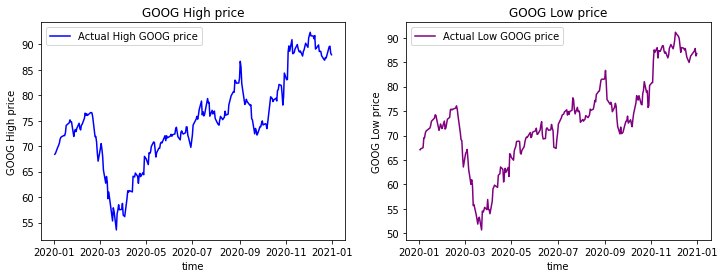

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(stock_data.High, color='b', label=f'Actual High {company} price')
ax1.set_title(f'{company} High price')
ax1.set_xlabel('time')
ax1.set_ylabel(f'{company} High price')
ax1.legend()
ax2.plot(stock_data.Low, color='purple', label=f'Actual Low {company} price')
ax2.set_title(f'{company} Low price')
ax2.set_xlabel('time')
ax2.set_ylabel(f'{company} Low price')
ax2.legend()

# In the final part, with the best model we had, we obtain and draw the prediction value for high and low.

In [ ]:
stock_data = df[['High','Low']]
stock_data = stock_data.to_numpy()
stock_data

In [ ]:
def create_dataset(dataset, seq_len=30):
	data_x = []
	for i in range(len(dataset)-seq_len-1):
		a = dataset[i:(i+seq_len), :]
		data_x.append(a)
	return np.array(data_x)

In [ ]:
train = create_dataset(stock_data, seq_len)
Train = torch.from_numpy(train).type(torch.Tensor)

In [ ]:
prediction = gru_model(Train)

In [ ]:
prediction = pd.DataFrame(scaler.inverse_transform(prediction.detach().numpy()))

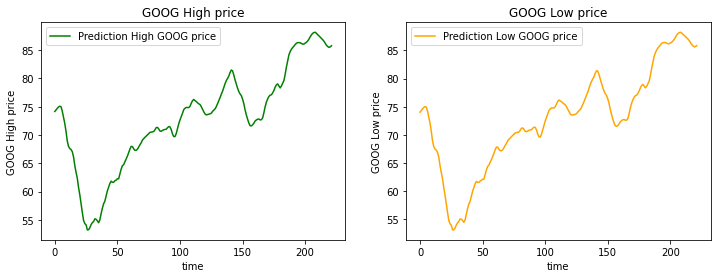

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(prediction[0], color='g', label=f'Prediction High {company} price')
ax1.set_title(f'{company} High price')
ax1.set_xlabel('time')
ax1.set_ylabel(f'{company} High price')
ax1.legend()
ax2.plot(prediction[1], color='orange', label=f'Prediction Low {company} price')
ax2.set_title(f'{company} Low price')
ax2.set_xlabel('time')
ax2.set_ylabel(f'{company} Low price')
ax2.legend()